#### ***Conditional Workflow***
- ***Non-LLM Workflow (Content Moderation System)***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

# Define State 
class ModerationState(TypedDict):
    post_content: str
    user_reputation: str
    formatted_post: str
    content_flag: str
    result: str

In [2]:
# Node_1: Post Format
def format_post(state: ModerationState):
    formatted = f"User ({state['user_reputation']}) says: {state['post_content']}"
    return {'formatted_post': formatted}

# Node_2: Content Analysis
def analyze_content(state: ModerationState):
    content = state['post_content'].lower()
    
    # Simple mock logic for content moderation
    if 'spam' in content or 'buy now' in content:
        flag = 'rejected'
    elif state['user_reputation'] == 'new_user':
        flag = 'review'
    else:
        flag = 'approved'
    return {'content_flag': flag}

# Node_3: Post Approval 
def approve_post(state: ModerationState):
    result = 'Post published successfully to the timeline.'
    return {'result': result}

# Node_4: Review 
def flag_for_review(state: ModerationState):
    result = 'Post sent to the human moderation queue.'
    return {'result': result}

# Node_5: Reject Post 
def reject_post(state: ModerationState):
    result = 'Post automatically deleted due to policy violation.'
    return {'result': result}

# Node_6: Check Final Logic
def check_condition(state: ModerationState) -> Literal["approve_post", "flag_for_review", "reject_post"]:
    if state['content_flag'] == 'approved':
        return "approve_post"
    elif state['content_flag'] == 'review':
        return "flag_for_review"
    else:
        return "reject_post"

In [3]:
# Build Graph 
graph = StateGraph(ModerationState)

# add the nodes
graph.add_node('format_post', format_post)
graph.add_node('analyze_content', analyze_content)
graph.add_node('approve_post', approve_post)
graph.add_node('flag_for_review', flag_for_review)
graph.add_node('reject_post', reject_post)


# add the edges
graph.add_edge(START, 'format_post')
graph.add_edge('format_post', 'analyze_content')

# Add conditional edges
graph.add_conditional_edges('analyze_content', check_condition)

# Connect all branches to END
graph.add_edge('approve_post', END)
graph.add_edge('flag_for_review', END)
graph.add_edge('reject_post', END)

workflow = graph.compile()

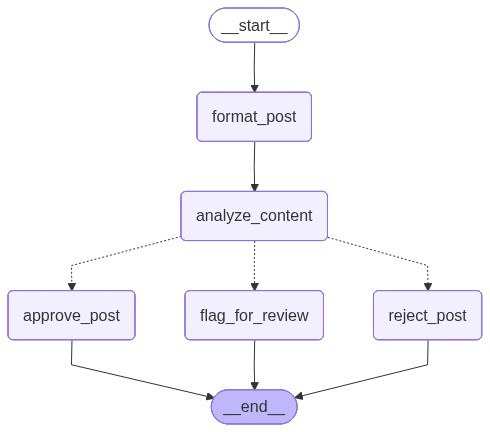

In [4]:
## Visualize Out Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [5]:
initial_state = {
    'post_content': "Check out this amazing new product!", 
    'user_reputation': "new_user"
}
result = workflow.invoke(initial_state)
result

{'post_content': 'Check out this amazing new product!',
 'user_reputation': 'new_user',
 'formatted_post': 'User (new_user) says: Check out this amazing new product!',
 'content_flag': 'review',
 'result': 'Post sent to the human moderation queue.'}

- ***LLM Based Workflow (Review Reply System)***

In [6]:
from langgraph.graph import StateGraph,START,END 
from langchain_groq import ChatGroq
from typing import TypedDict,Literal
from pydantic import BaseModel,Field

from dotenv import  load_dotenv
load_dotenv()

True

In [7]:
# Define Our Model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [8]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative"] = Field(description='Sentiment of the review')

class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

structured_model = llm.with_structured_output(SentimentSchema)
structured_model2 = llm.with_structured_output(DiagnosisSchema)

In [9]:
# Define State
class ReviewState(TypedDict):
    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str

In [10]:
# Node_1: Find Sentiment 
def find_sentiment(state: ReviewState):
    prompt = f'For the following review find out the sentiment \n {state["review"]}'
    response = structured_model.invoke(prompt)
    sentiment = response["sentiment"]

    return {
        'sentiment': sentiment
    }

# Node_2: Positive Response 
def positive_response(state: ReviewState):
    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
    Also, kindly ask the user to leave feedback on our website."""

    response = llm.invoke(prompt).content
    return {'response': response}

# Node_3: Diagnosis
def run_diagnosis(state: ReviewState):
    prompt = f"""Diagnose this negative review:\n\n{state   ['review']}\n"
        "Return issue_type, tone, and urgency.
        """
    
    response = structured_model2.invoke(prompt)
    return {'diagnosis': response.model_dump()}

# Node_4: Negative Response 
def negative_response(state: ReviewState):
    diagnosis = state['diagnosis']
    prompt = f"""You are a support assistant.
        The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
        Write an empathetic, helpful resolution message.
        """
    response = llm.invoke(prompt).content
    return {'response': response}

In [11]:
# Check Sentiment 
def check_sentiment(state: ReviewState) -> Literal["positive_response", "run_diagnosis"]:
    if state['sentiment'] == 'positive':
        return 'positive_response'
    else:
        return 'run_diagnosis'

In [12]:
# Build Graph 
graph = StateGraph(ReviewState)

# add nodes
graph.add_node('find_sentiment', find_sentiment)
graph.add_node('positive_response', positive_response)
graph.add_node('run_diagnosis', run_diagnosis)
graph.add_node('negative_response', negative_response)

# add edges with conditions
graph.add_edge(START, 'find_sentiment')

graph.add_conditional_edges('find_sentiment', check_sentiment)
graph.add_edge('positive_response', END)

graph.add_edge('run_diagnosis', 'negative_response')
graph.add_edge('negative_response', END)

workflow = graph.compile()

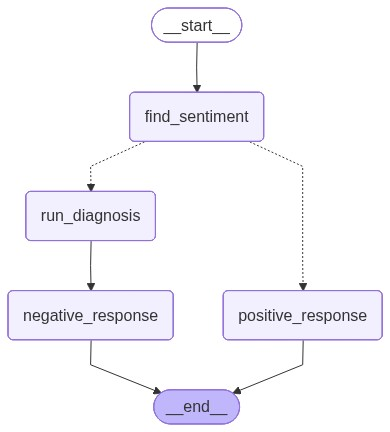

In [13]:
## Visualize Out Graph 
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [15]:
intial_state={
    'review': "Excellent software with a clean interface and smooth performance. It has improved our workflow significantly and saved a lot of time. Highly recommended for anyone looking for a reliable tech solution!"
}
result = workflow.invoke(intial_state)

In [16]:
for key, value in result.items():
    print(f"{key.upper()}:")
    print(value)
    print("-" * 50)

REVIEW:
Excellent software with a clean interface and smooth performance. It has improved our workflow significantly and saved a lot of time. Highly recommended for anyone looking for a reliable tech solution!
--------------------------------------------------
SENTIMENT:
positive
--------------------------------------------------
RESPONSE:
Dear [Customer Name],

Thank you so much for your wonderful review! We’re thrilled to hear that our software’s clean interface and smooth performance have made a real difference in your workflow and saved you valuable time. Your kind words and recommendation mean the world to us and motivate our team to keep delivering reliable, high‑quality solutions.

If you have a moment, we’d greatly appreciate it if you could share your experience on our website as well. Your feedback helps other users discover the benefits of our product and guides us in continuing to improve.

Thanks again for your support and for being a valued part of our community!

Warm re